# Credit Card Fraud Detection

Predicting `is_fraud` for 100K card transactions from 2026 (Kaggle:
`mohankrishnathalla/credit-card-fraud-detection-dataset-2026`).

**Setup:** the model is trained on **Jan–Sep** and tested on **Oct–Dec**, the
way a fraud model is used in practice (learn from the past, score the future).
To keep the test months truly unseen, every EDA finding that turns into a
feature cutoff is computed on **Jan–Sep only**.

In [1]:
# imports + settings
import kagglehub
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    "figure.facecolor":  "#ffffff",
    "axes.facecolor":    "#f9f9f9",
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.grid":         True,
    "grid.color":        "#e5e5e5",
    "grid.linewidth":    0.6,
    "font.family":       "Helvetica",
    "font.size":         11,
})

BLUE    =   "#151B54"
RED     =   "#BF2C34"
ORANGE  =   "#FC6238"
GREEN   =   "#009D52"
PURPLE  =   "#4c00b0"

# download latest version
path = kagglehub.dataset_download("mohankrishnathalla/credit-card-fraud-detection-dataset-2026")
file_path = os.path.join(path, "credit_card_fraud_detection_2026.csv")
fraud_df = pd.read_csv(file_path)

# make extra temporal features
fraud_df["transaction_datetime"] = pd.to_datetime(fraud_df["transaction_datetime"])
fraud_df["transaction_month"] = fraud_df["transaction_datetime"].dt.month
fraud_df["transaction_date"] = fraud_df["transaction_datetime"].dt.date

# train = Jan-Sep, test = Oct-Dec (see the Model section)
TRAIN_MONTHS = range(1, 10)
train_df = fraud_df[fraud_df["transaction_month"].isin(TRAIN_MONTHS)].copy()

# initial info
print(f"shape: {fraud_df.shape}")
print(f"missing values: {fraud_df.isnull().sum().sum()}")
print(f"date range: {fraud_df.transaction_datetime.min()} - {fraud_df.transaction_datetime.max()}")
print(f"unique customers: {fraud_df.customer_id.nunique()}")
print(f"unique merchants: {fraud_df.merchant_id.nunique()}")
print(f"overall fraud rate: {fraud_df.is_fraud.mean():.2%}")
print(f"train (Jan-Sep) rows: {len(train_df)}, fraud rate: {train_df.is_fraud.mean():.2%}")

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shape: (100000, 45)
missing values: 41709
date range: 2026-01-01 02:28:51 - 2026-12-31 23:45:47
unique customers: 8000
unique merchants: 3000
overall fraud rate: 2.05%
train (Jan-Sep) rows: 74663, fraud rate: 2.02%


### What to look into ###
- class imbalance
- temporal features
- merchant features
- transaction features

In [2]:
fraud_df.dtypes

transaction_id                            str
customer_id                               str
card_id                                   str
merchant_id                               str
transaction_datetime           datetime64[us]
transaction_amount                    float64
merchant_category                         str
merchant_country                          str
transaction_hour                        int64
transaction_day_of_week                   str
card_present                            int64
customer_age                            int64
customer_gender                           str
customer_state                            str
account_age_days                        int64
credit_limit                          float64
credit_score                            int64
num_cards_held                          int64
transactions_last_1h                    int64
transactions_last_24h                   int64
transactions_last_7d                    int64
amount_last_1h                    

### Exploratory Data Analysis (EDA) ###

In [3]:
pd.set_option("display.max_columns", None)
fraud_df.describe().round(2)

,transaction_datetime,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,is_fraud,fraud_amount_lost,transaction_month
count,100000,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,2026-07-02 11:04:30.563410,126.87,14.39,0.36,42.22,785.45,10083.18,682.33,2.20,0.78,2.95,8.84,96.89,367.71,3.50,4316.75,939.44,0.55,0.05,1.96,0.31,0.18,0.28,124.40,68.46,0.51,0.37,0.02,2.80,6.52
min,2026-01-01 02:28:51,0.50,0.00,0.00,18.00,1.00,500.00,328.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.38,2.46,0.00,0.00,0.00,0.00,1.00
25%,2026-04-01 08:31:50.250000,21.28,11.00,0.00,32.00,233.00,5000.00,620.00,1.00,0.00,1.00,4.00,0.00,77.63,1.00,20.60,5.20,0.00,0.00,0.21,0.00,0.00,0.00,52.46,26.88,0.00,0.00,0.00,0.00,4.00
50%,2026-07-02 17:46:21.500000,52.26,14.00,0.00,42.00,554.00,8500.00,683.00,2.00,0.00,2.00,7.00,0.00,197.70,2.40,1949.95,13.30,1.00,0.00,0.58,0.00,0.00,0.00,89.37,48.17,0.00,0.00,0.00,0.00,7.00
75%,2026-10-02 08:26:00.500000,129.72,19.00,1.00,52.00,1103.00,13650.00,748.00,3.00,1.00,4.00,12.00,100.01,445.41,4.80,8482.35,31.90,1.00,0.00,1.66,1.00,0.00,1.00,155.08,85.42,1.00,0.00,0.00,0.00,10.00
max,2026-12-31 23:45:47,15000.00,23.00,1.00,85.00,3650.00,36670.00,850.00,5.00,8.00,18.00,42.00,11421.39,15161.52,47.30,14999.80,11999.60,1.00,1.00,686.32,1.00,1.00,1.00,2000.00,1334.92,5.00,4.00,1.00,4482.16,12.00
std,NaN,276.18,5.02,0.48,14.25,747.49,6510.65,92.12,1.16,1.35,2.38,6.36,252.18,551.65,3.52,4946.79,2551.11,0.50,0.22,6.37,0.46,0.39,0.45,119.71,70.83,1.01,0.79,0.14,43.67,3.46


In [4]:
def _null_counts(df: pd.DataFrame):
    nulls = {}
    for col in df.columns:
        nulls[col] = df[col].isna().sum()
    nulls_df  = pd.DataFrame(list(nulls.items()), columns=["column", "nulls"])
    # display cols with nulls
    nulls_df = nulls_df[nulls_df["nulls"] > 0].reset_index(drop=True)
    return nulls_df

nulls_df = _null_counts(fraud_df)
display(nulls_df)

,column,nulls
0,browser,41709


In [5]:
# cat distributions
cat_cols = ["merchant_category", "merchant_country", "customer_gender", "customer_state", "transaction_channel", "device_type", "browser", "email_domain", "transaction_day_of_week"]
for col in cat_cols:
    print(fraud_df[col].value_counts().to_string())
    print()

merchant_category
Online Retail                13417
Restaurant & Dining          12736
Grocery & Supermarket        12137
Gas Station                  10885
Healthcare & Pharmacy         7903
Electronics & Technology      6934
Travel & Airlines             6612
Hotel & Lodging               6360
Clothing & Apparel            6324
Entertainment & Streaming     5848
Auto & Transportation         3974
Home Improvement              3824
Education                     1137
Utilities & Telecom           1036
Financial Services             873

merchant_country
USA             44515
UK               8349
Canada           7238
Germany          5651
Australia        5423
France           4521
Italy            3344
Netherlands      3039
Spain            2849
Brazil           2354
India            2175
Mexico           1921
China            1682
Nigeria          1261
South Africa     1140
Russia           1046
Romania           943
UAE               940
Japan             821
South Korea       788

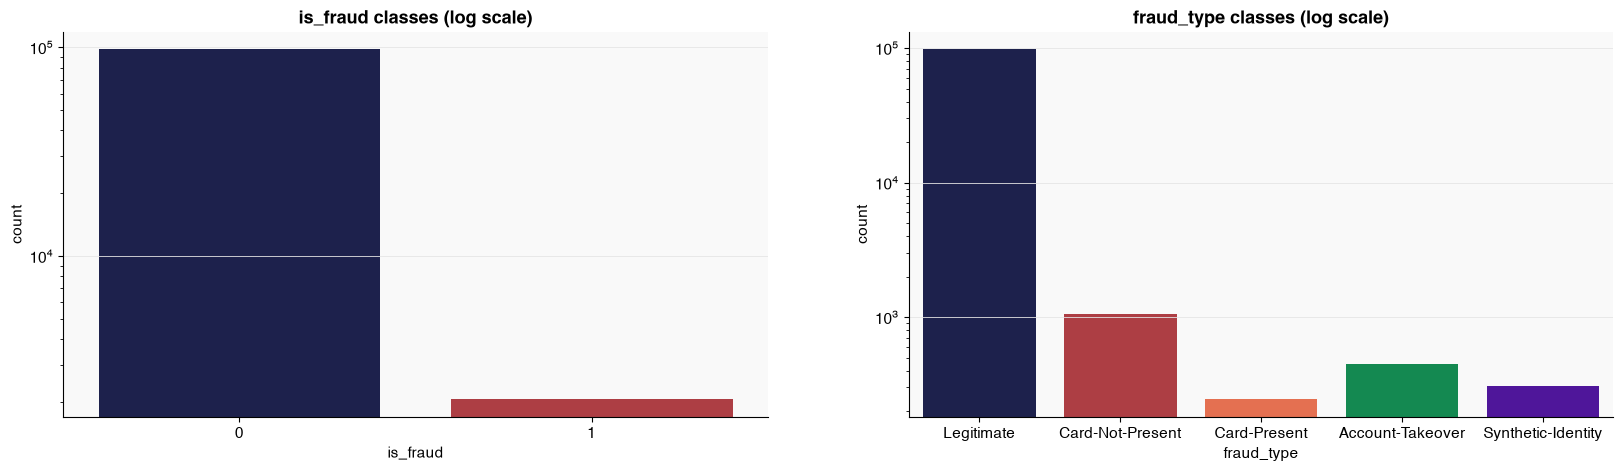

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(20, 5))

# is_fraud class distribution
sns.countplot(
    data=fraud_df,
    x="is_fraud",
    hue="is_fraud",
    palette=[BLUE, RED],
    ax=ax[0],
    legend=False,
)
ax[0].set_yscale("log", nonpositive="clip")
ax[0].set_title("is_fraud classes (log scale)", fontweight="bold")

# fraud_type class distribution
sns.countplot(
    data=fraud_df,
    x="fraud_type",
    hue="fraud_type",
    palette=[BLUE, RED, ORANGE, GREEN, PURPLE],
    ax=ax[1],
    legend=False
)
ax[1].set_yscale("log", nonpositive="clip")
ax[1].set_title("fraud_type classes (log scale)", fontweight="bold")

plt.show()

From here on, the EDA runs on **`train_df` (Jan–Sep)** so the cutoffs it
suggests never peek at the Oct–Dec test months. `baseline` is the Jan–Sep
fraud rate.

In [7]:
def fraud_rate_by(df, col):
    """Fraud count, total and fraud rate (%) for each value of col."""
    out = df.groupby(col, observed=True).agg(
        fraud=("is_fraud", "sum"),
        total=("is_fraud", "count"),
    ).reset_index()
    out["fraud_rate"] = (out["fraud"] / out["total"] * 100).round(2)
    return out

baseline = round(train_df["is_fraud"].mean() * 100, 2)
print(f"baseline fraud rate (Jan-Sep): {baseline}%")

baseline fraud rate (Jan-Sep): 2.02%


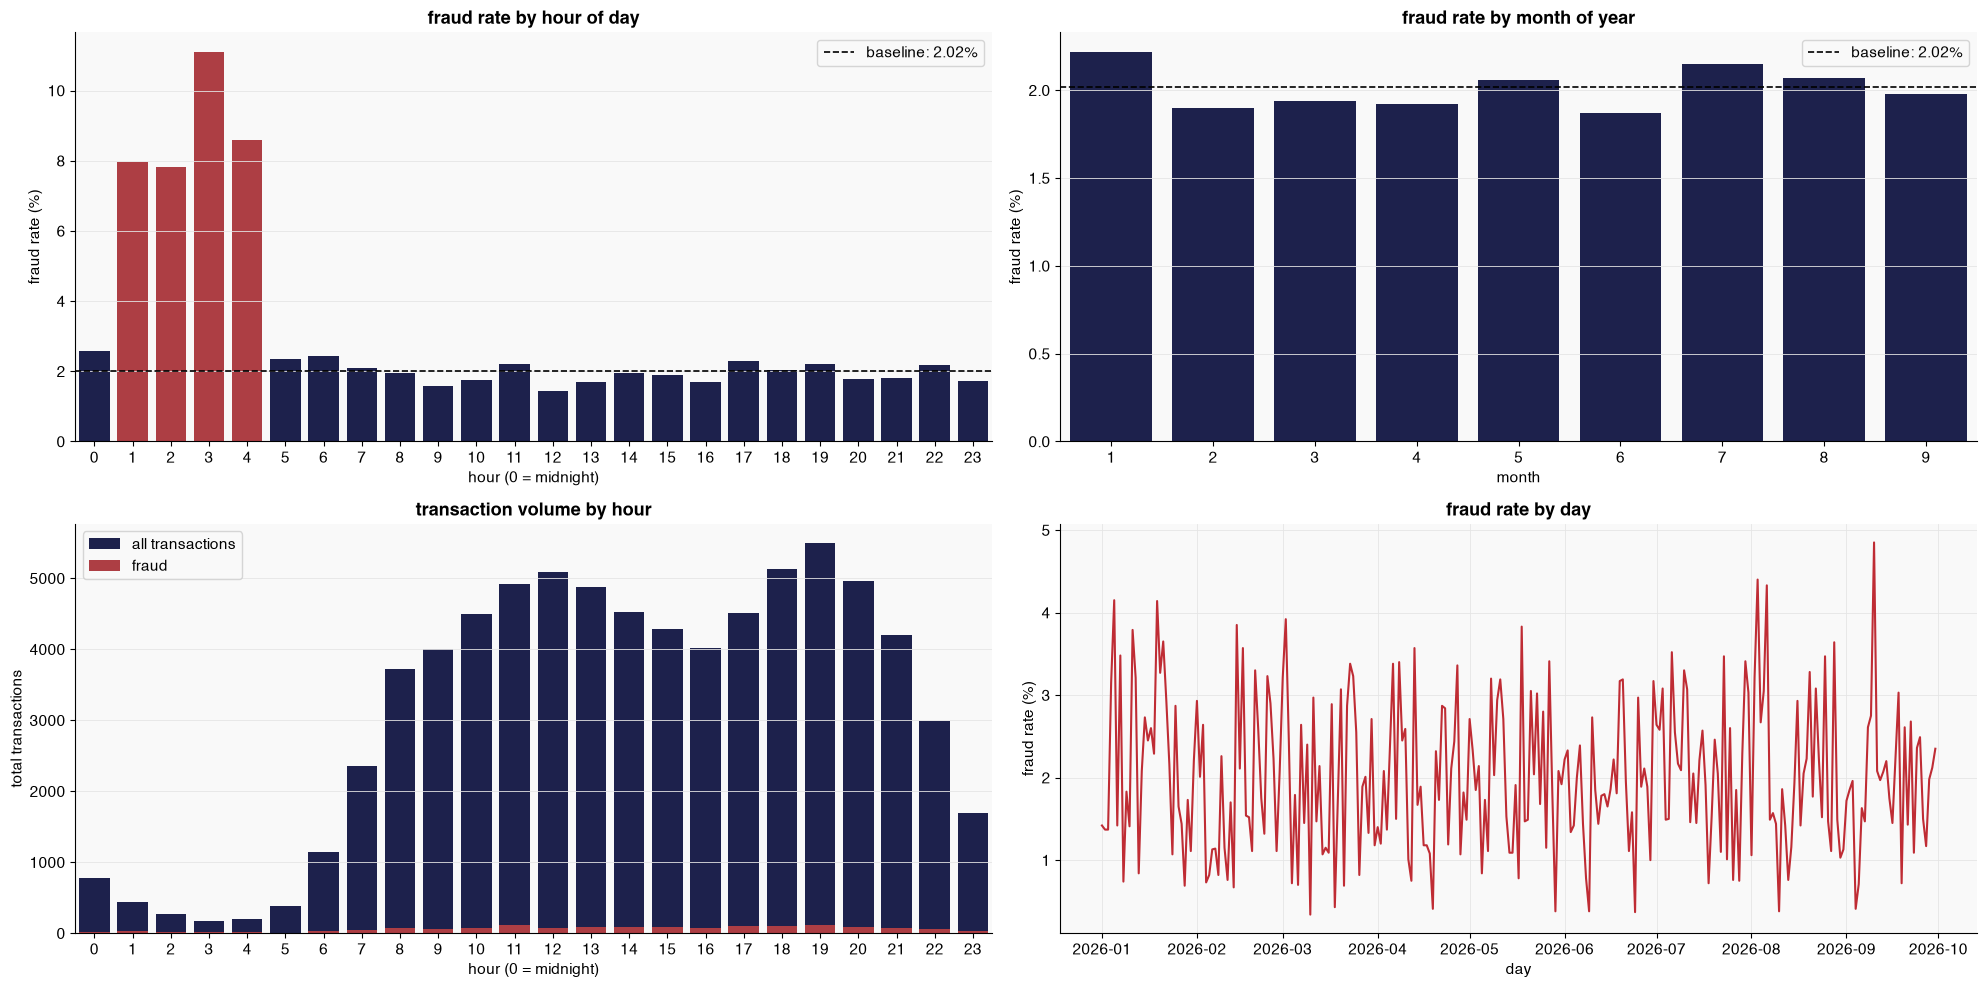

hours with high fraud rates:
 transaction_hour  fraud_rate
                0        2.58
                2        7.81
                1        7.97
                4        8.59
                3       11.11

days with high fraud rates:
transaction_date  fraud_rate
      2026-01-19        4.14
      2026-01-05        4.15
      2026-08-06        4.33
      2026-08-03        4.40
      2026-09-10        4.85


In [8]:
# temporal analysis
fig, ax = plt.subplots(2, 2, figsize=(20, 10))

# % fraud per hour
hourly = fraud_rate_by(train_df, "transaction_hour")

# color massive outliers red
hour_colors = [RED if rate > baseline * 1.5 else BLUE for rate in hourly["fraud_rate"]]

sns.barplot(
    data=hourly,
    x="transaction_hour",
    y="fraud_rate",
    hue="transaction_hour",
    palette=hour_colors,
    ax=ax[0,0],
    legend=False
)

ax[0,0].set_xlabel("hour (0 = midnight)")
ax[0,0].set_ylabel("fraud rate (%)")
ax[0,0].axhline(baseline, color="black", linewidth=1.2, linestyle="--", label=f"baseline: {baseline}%")
ax[0,0].legend()
ax[0,0].set_title("fraud rate by hour of day", fontweight="bold")

# % fraud per month
monthly = fraud_rate_by(train_df, "transaction_month")

# color massive outliers red
month_colors = [RED if rate > baseline * 1.5 else BLUE for rate in monthly["fraud_rate"]]

sns.barplot(
    data=monthly,
    x="transaction_month",
    y="fraud_rate",
    hue="transaction_month",
    palette=month_colors,
    ax=ax[0,1],
    legend=False
)

ax[0,1].set_xlabel("month")
ax[0,1].set_ylabel("fraud rate (%)")
ax[0,1].axhline(baseline, color="black", linewidth=1.2, linestyle="--", label=f"baseline: {baseline}%")
ax[0,1].legend()
ax[0,1].set_title("fraud rate by month of year", fontweight="bold")

# transaction volume per hour
sns.barplot(
    data=hourly,
    x="transaction_hour",
    y="total",
    color=BLUE,
    ax=ax[1,0],
    label="all transactions"
)
# total amount of fraud out of total transactions
sns.barplot(
    data=hourly,
    x="transaction_hour",
    y="fraud",
    color=RED,
    ax=ax[1,0],
    label="fraud"
)

ax[1,0].set_xlabel("hour (0 = midnight)")
ax[1,0].set_ylabel("total transactions")
ax[1,0].set_title("transaction volume by hour", fontweight="bold")

# top days for fraud
daily = fraud_rate_by(train_df, "transaction_date")

sns.lineplot(
    data=daily,
    x="transaction_date",
    y="fraud_rate",
    color=RED,
    ax=ax[1,1],
)

ax[1,1].set_xlabel("day")
ax[1,1].set_ylabel("fraud rate (%)")
ax[1,1].set_title("fraud rate by day", fontweight="bold")

plt.tight_layout()
plt.show()

print("hours with high fraud rates:")
print(hourly[["transaction_hour", "fraud_rate"]].sort_values(by="fraud_rate").tail(5).to_string(index=False))
print()
print("days with high fraud rates:")
print(daily[["transaction_date", "fraud_rate"]].sort_values(by="fraud_rate").tail(5).to_string(index=False))

### Temporal Features ###
- Large fraud rate spikes between hours 1 - 4: 8-11% vs the 2.02% baseline (hour 3 is the worst at 11.1%). Hour 0 is only slightly above baseline.
- Fraud is pretty general across the year and months; no visible spikes. The daily rate bounces between 0-5% with no seasonal pattern.

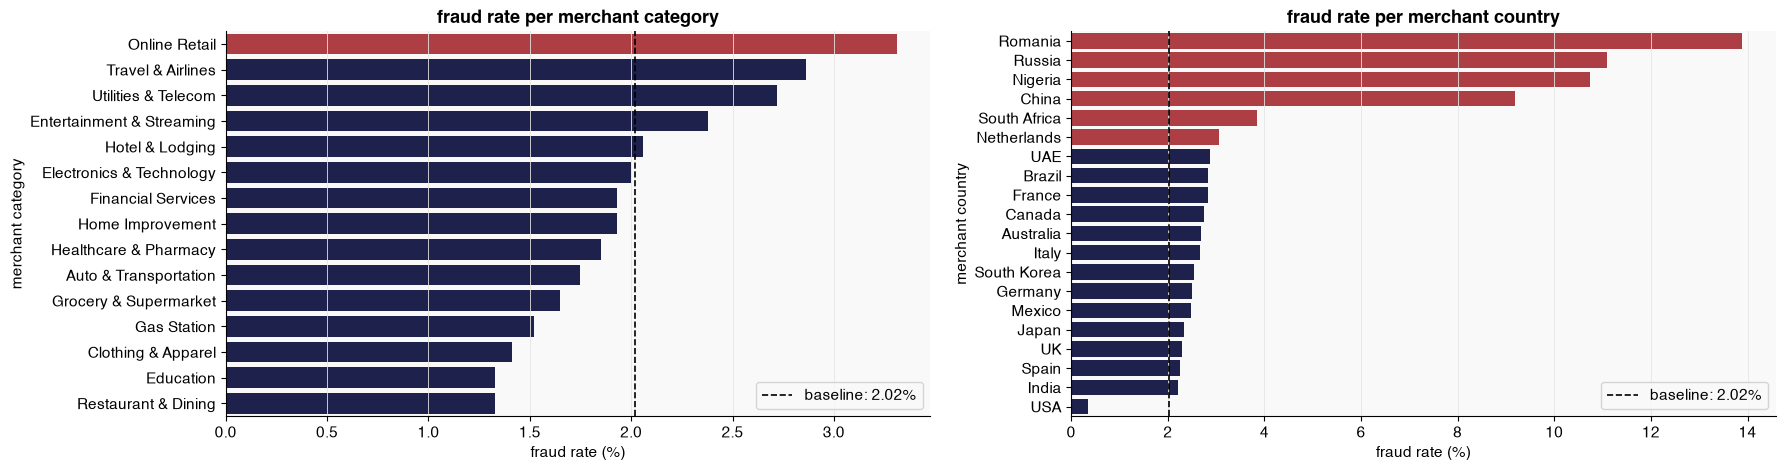

risky countries (>= 3x baseline in Jan-Sep): ['Romania', 'Russia', 'Nigeria', 'China']

        merchant_category  fraud_rate
            Online Retail        3.31
        Travel & Airlines        2.86
      Utilities & Telecom        2.72
Entertainment & Streaming        2.38
          Hotel & Lodging        2.06


In [9]:
# merchant profile analysis
fig, ax = plt.subplots(1, 2, figsize=(20, 5))

# % fraud for each merchant category
merchant_cat = fraud_rate_by(train_df, "merchant_category").sort_values(by="fraud_rate", ascending=False)
merchant_cat_colors = [RED if rate > baseline * 1.5 else BLUE for rate in merchant_cat["fraud_rate"]]

sns.barplot(
    data=merchant_cat,
    x="fraud_rate",
    y="merchant_category",
    hue="merchant_category",
    ax=ax[0],
    palette=merchant_cat_colors
)

ax[0].set_xlabel("fraud rate (%)")
ax[0].set_ylabel("merchant category")
ax[0].axvline(baseline, color="black", linewidth=1.2, linestyle="--", label=f"baseline: {baseline}%")
ax[0].legend()
ax[0].set_title("fraud rate per merchant category", fontweight="bold")

# % fraud for each merchant country
merchant_country = fraud_rate_by(train_df, "merchant_country").sort_values(by="fraud_rate", ascending=False)
merchant_country_colors = [RED if rate > baseline * 1.5 else BLUE for rate in merchant_country["fraud_rate"]]

sns.barplot(
    data=merchant_country,
    x="fraud_rate",
    y="merchant_country",
    hue="merchant_country",
    ax=ax[1],
    palette=merchant_country_colors
)

ax[1].set_xlabel("fraud rate (%)")
ax[1].set_ylabel("merchant country")
ax[1].axvline(baseline, color="black", linewidth=1.2, linestyle="--", label=f"baseline: {baseline}%")
ax[1].legend()
ax[1].set_title("fraud rate per merchant country", fontweight="bold")

plt.show()

# countries far above baseline (>= 3x) become the "risky" list used in feature engineering
RISKY_COUNTRIES = merchant_country.loc[merchant_country["fraud_rate"] >= baseline * 3, "merchant_country"].tolist()
print(f"risky countries (>= 3x baseline in Jan-Sep): {RISKY_COUNTRIES}")
print()
print(merchant_cat[["merchant_category", "fraud_rate"]].head(5).to_string(index=False))

### Merchant Features ###
- Online Retail (3.3%) and Travel & Airlines (2.9%) have the highest fraud rates by category, but the gaps between categories are small.
- Romania, Russia, Nigeria, and China all have fraud rates at least 3x the 2.02% baseline, far above every other merchant country. They become `RISKY_COUNTRIES` for feature engineering.

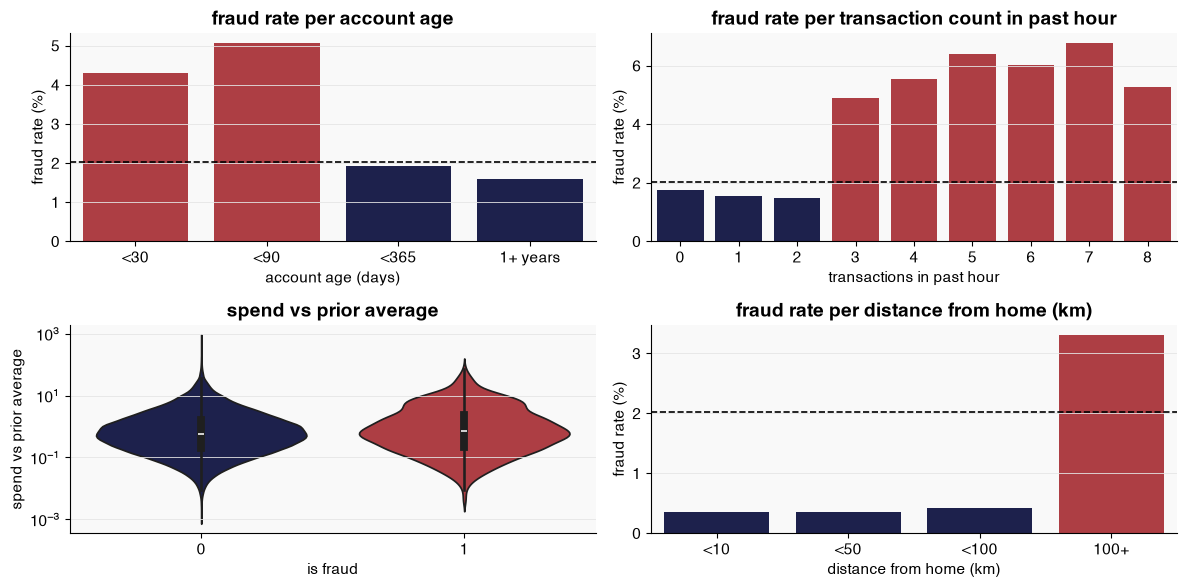

account age
account_age_bins  fraud  total  fraud_rate
             <30    114   2644        4.31
             <90    266   5244        5.07
            <365    368  19209        1.92
        1+ years    757  47566        1.59

transactions in past hour
 transactions_last_1h  fraud  total  fraud_rate
                    0    782  44755        1.75
                    1    254  16343        1.55
                    2    100   6803        1.47
                    3    147   3008        4.89
                    4     83   1495        5.55
                    5     48    749        6.41
                    6     47    781        6.02
                    7     25    369        6.78
                    8     19    360        5.28

distance from home
distance_from_home_km_bins  fraud  total  fraud_rate
                       <10     39  11107        0.35
                       <50     62  17754        0.35
                      <100     16   3831        0.42
                      100+   1388 

In [10]:
# customer analysis
fig, ax = plt.subplots(2, 2, figsize=(12,6))
eda = train_df.copy()

# fraud rate by account age
edges = [-1, 30, 90, 365, np.inf]
groups = ["<30", "<90", "<365", "1+ years"]
eda["account_age_bins"] = pd.cut(eda["account_age_days"], bins=edges, labels=groups)

account_age = fraud_rate_by(eda, "account_age_bins")

sns.barplot(
    data=account_age,
    x="account_age_bins",
    y="fraud_rate",
    hue="account_age_bins",
    palette=[RED if rate > baseline * 1.5 else BLUE for rate in account_age["fraud_rate"]],
    dodge=False,
    legend=False,
    ax=ax[0,0]
)

ax[0,0].axhline(baseline, color="black", linewidth=1.2, linestyle="--")
ax[0,0].set_title("fraud rate per account age", fontsize=14, fontweight="bold")
ax[0,0].set_xlabel("account age (days)")
ax[0,0].set_ylabel("fraud rate (%)")

# fraud rate by transaction count
transactions_past_hour = fraud_rate_by(eda, "transactions_last_1h")

sns.barplot(
    data=transactions_past_hour,
    x="transactions_last_1h",
    y="fraud_rate",
    hue="transactions_last_1h",
    palette=[RED if rate > baseline * 1.5 else BLUE for rate in transactions_past_hour["fraud_rate"]],
    dodge=False,
    legend=False,
    ax=ax[0,1]
)

ax[0,1].axhline(baseline, color="black", linewidth=1.2, linestyle="--")
ax[0,1].set_title("fraud rate per transaction count in past hour", fontsize=14, fontweight="bold")
ax[0,1].set_xlabel("transactions in past hour")
ax[0,1].set_ylabel("fraud rate (%)")

# fraud rate by spend vs prior average
sns.violinplot(
    data=eda,
    x="is_fraud",
    y="amount_vs_avg_ratio",
    hue="is_fraud",
    palette=[BLUE, RED],
    log_scale=True,
    legend=False,
    ax=ax[1,0]
)

ax[1,0].set_title("spend vs prior average", fontsize=14, fontweight="bold")
ax[1,0].set_xlabel("is fraud")
ax[1,0].set_ylabel("spend vs prior average")

# fraud rate by distance from home
edges = [-1, 10, 50, 100, np.inf]
groups = ["<10", "<50", "<100", "100+"]
eda["distance_from_home_km_bins"] = pd.cut(eda["distance_from_home_km"], bins=edges, labels=groups)

distance_from_home = fraud_rate_by(eda, "distance_from_home_km_bins")

sns.barplot(
    data=distance_from_home,
    x="distance_from_home_km_bins",
    y="fraud_rate",
    hue="distance_from_home_km_bins",
    palette=[RED if rate > baseline * 1.5 else BLUE for rate in distance_from_home["fraud_rate"]],
    dodge=False,
    legend=False,
    ax=ax[1,1]
)

ax[1,1].axhline(baseline, color="black", linewidth=1.2, linestyle="--")
ax[1,1].set_title("fraud rate per distance from home (km)", fontsize=14, fontweight="bold")
ax[1,1].set_xlabel("distance from home (km)")
ax[1,1].set_ylabel("fraud rate (%)")

plt.tight_layout()
plt.show()

for name, table in [("account age", account_age), ("transactions in past hour", transactions_past_hour), ("distance from home", distance_from_home)]:
    print(name)
    print(table.to_string(index=False))
    print()

### Account-Holder Features ###
- Accounts younger than 90 days have a much higher rate of fraud (4.3-5.1% vs 1.6-1.9% for older accounts).
- Three or more transactions in the past hour also show higher fraud rates (4.9-6.8% vs at most 1.75% below three). Large amounts of transactions tend to be a good velocity feature in flagging fraud.
- Transactions 100+ km from home have a 3.3% fraud rate vs ~0.4% under 100 km, about 9x higher. This is the strongest single split found.

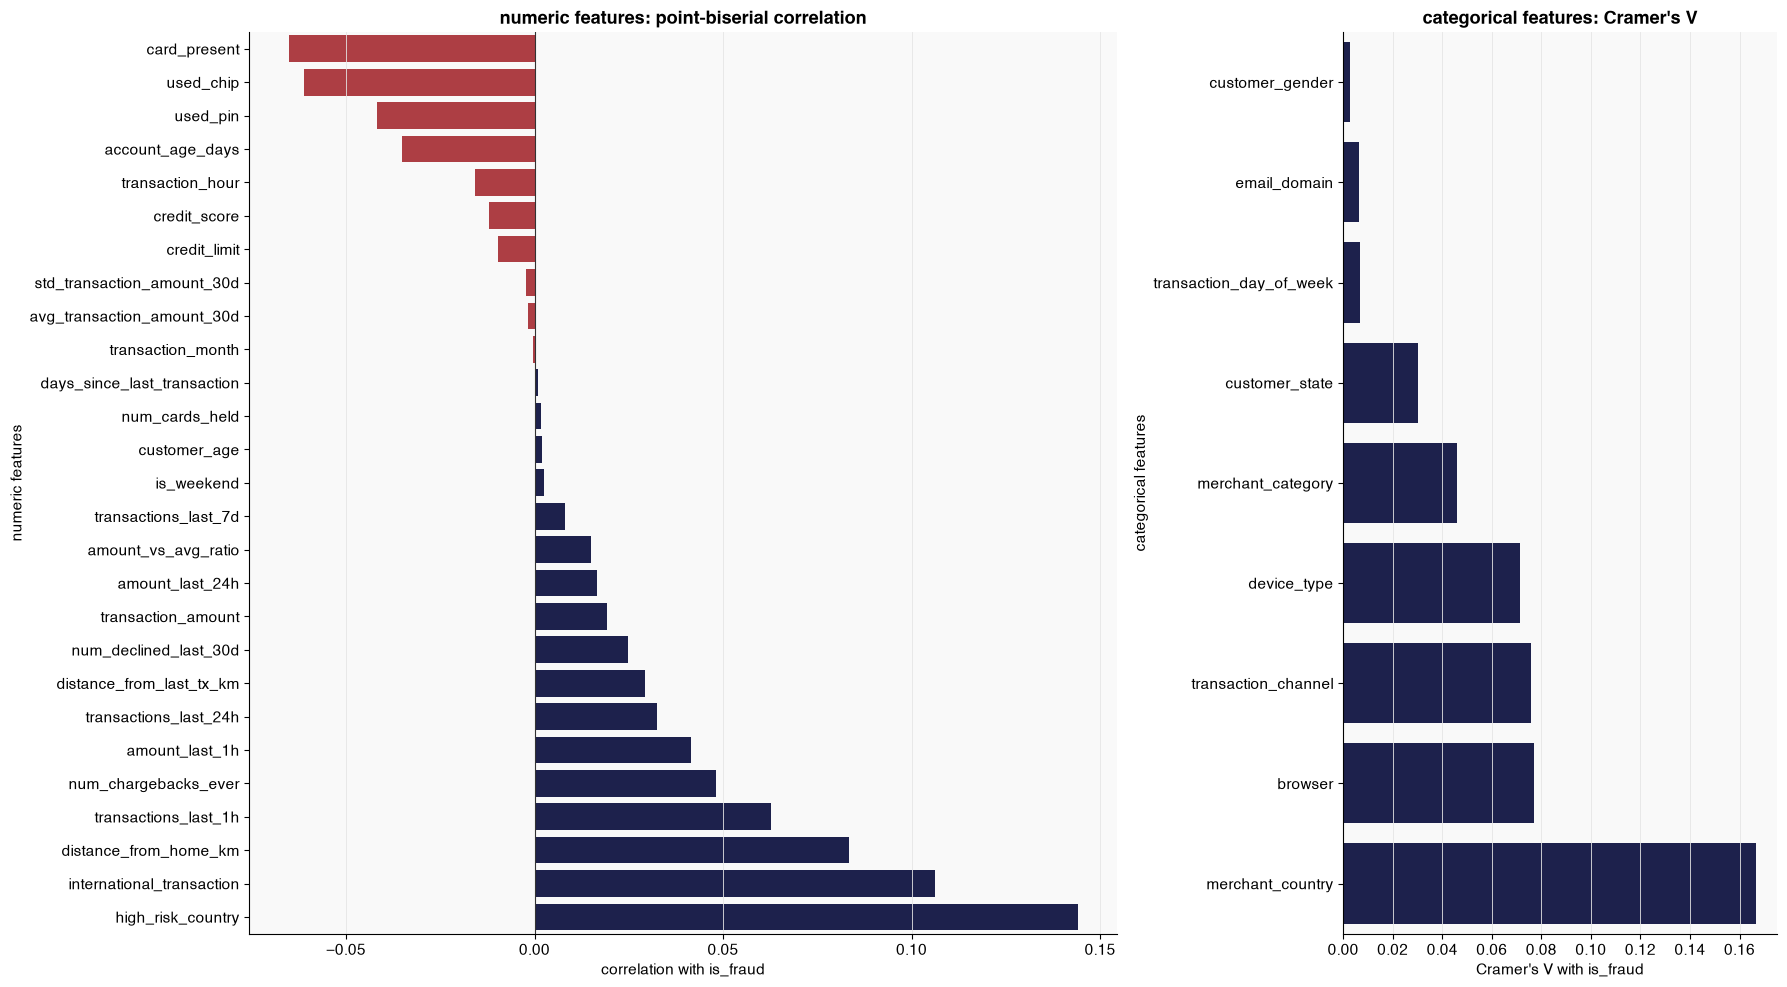

top 10 positive correlations with fraud:
transaction_amount           0.019
num_declined_last_30d        0.025
distance_from_last_tx_km     0.029
transactions_last_24h        0.032
amount_last_1h               0.042
num_chargebacks_ever         0.048
transactions_last_1h         0.063
distance_from_home_km        0.083
international_transaction    0.106
high_risk_country            0.144

top 5 negative correlations with fraud:
card_present       -0.065
used_chip          -0.061
used_pin           -0.042
account_age_days   -0.035
transaction_hour   -0.016

categorical associations:
merchant_country           0.167
browser                    0.077
transaction_channel        0.076
device_type                0.071
merchant_category          0.046
customer_state             0.030
transaction_day_of_week    0.007
email_domain               0.006
customer_gender            0.003


In [11]:
# how each feature relates to is_fraud (Jan-Sep)
# numeric features: point-biserial correlation (Pearson with a 0/1 target)
# categorical features: Cramer's V (0 = no association, 1 = perfect); Pearson on
# label-encoded categories would depend on the arbitrary code order, so it isn't used
from scipy.stats import chi2_contingency

ids = ["transaction_id", "customer_id", "merchant_id", "card_id", "transaction_datetime", "transaction_date"]
targets = ["is_fraud", "fraud_type", "fraud_amount_lost"]
features = train_df.drop(columns=ids + targets)

numeric_features = features.select_dtypes(include="number").columns
categorical_features = features.columns.difference(numeric_features)

num_corr = features[numeric_features].corrwith(train_df["is_fraud"]).sort_values()

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

cat_assoc = pd.Series(
    {col: cramers_v(features[col].fillna("Unknown"), train_df["is_fraud"]) for col in categorical_features}
).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(18, 10), gridspec_kw={"width_ratios": [2, 1]})

sns.barplot(
    x=num_corr.values,
    y=num_corr.index,
    hue=num_corr.index,
    palette=[RED if c < 0 else BLUE for c in num_corr.values],
    legend=False,
    ax=ax[0],
)
ax[0].axvline(0, color="#333", linewidth=0.8)
ax[0].set_xlabel("correlation with is_fraud")
ax[0].set_ylabel("numeric features")
ax[0].set_title("numeric features: point-biserial correlation", fontweight="bold")

sns.barplot(x=cat_assoc.values, y=cat_assoc.index, color=BLUE, ax=ax[1])
ax[1].set_xlabel("Cramer's V with is_fraud")
ax[1].set_ylabel("categorical features")
ax[1].set_title("categorical features: Cramer's V", fontweight="bold")

plt.tight_layout()
plt.show()

print("top 10 positive correlations with fraud:")
print(num_corr.tail(10).round(3).to_string())
print()
print("top 5 negative correlations with fraud:")
print(num_corr.head(5).round(3).to_string())
print()
print("categorical associations:")
print(cat_assoc.sort_values(ascending=False).round(3).to_string())

Features that convey distance and foreign activity are the strongest signals
(`high_risk_country` 0.14, `international_transaction` 0.11,
`distance_from_home_km` 0.08), followed by velocity features such as
transactions in the past hour and chargebacks. Card-present, chip and PIN
transactions are less likely to be fraud. `merchant_country` is the strongest
categorical feature (Cramer's V 0.17), while customer demographics (gender,
state) and day of week carry almost no signal.

Every individual correlation is weak (all below 0.15), so no single feature
separates fraud from legit transactions. That is an early sign the models will
have modest scores.

In [12]:
# cleaning
fraud_df["browser"] = fraud_df["browser"].fillna("Unknown")
# sort df for temporal split
fraud_df = fraud_df.sort_values(by="transaction_datetime", ascending=True)

### Feature Engineering ###
Every cutoff below comes from the Jan–Sep EDA above. The combined
`fraud_suspicious_score` weights each flag by its **log lift** in Jan–Sep
(`ln(fraud rate when flagged / baseline)`), so the weights are learned from
training data instead of picked by hand.

In [13]:
# hours from 1-4 have higher fraud rates
fraud_df["is_night"] = fraud_df["transaction_hour"].isin([1, 2, 3, 4]).astype(int)

# transactions 3+ within the last hour have higher fraud rates
fraud_df["frequent_transactions_past_1h"] = (fraud_df["transactions_last_1h"] >= 3).astype(int)

# transaction far from home
fraud_df["is_far"] = (fraud_df["distance_from_home_km"] > 100).astype(int)

fraud_df["high_chargeback_amount"] = (fraud_df["num_chargebacks_ever"] > 2).astype(int)

# far from the last transaction in little time = suspicious ("impossible travel").
# +0.1 day keeps same-day transactions finite instead of dividing by zero
fraud_df["km_per_day_since_last_tx"] = (fraud_df["distance_from_last_tx_km"] / (fraud_df["days_since_last_transaction"] + 0.1)).round(2)

# account is new <90 days
fraud_df["new_account"] = (fraud_df["account_age_days"] < 90).astype(int)

# online retail in a risky country (RISKY_COUNTRIES comes from the Jan-Sep merchant EDA)
fraud_df["suspicious_purchase"] = ((fraud_df["merchant_category"] == "Online Retail") & (fraud_df["merchant_country"].isin(RISKY_COUNTRIES))).astype(int)

# share of the last 24h spend that happened in the last hour (no 24h spend -> 0)
fraud_df["amount_last_1h_24h_ratio"] = (fraud_df["amount_last_1h"] / fraud_df["amount_last_24h"].replace(0, np.nan)).fillna(0).round(2)

# transaction amount 30d zscore
fraud_df["transaction_30d_zscore"] = ((fraud_df["transaction_amount"] - fraud_df["avg_transaction_amount_30d"]) / fraud_df["std_transaction_amount_30d"]).round(2)

fraud_df["high_30d_zscore"] = (fraud_df["transaction_30d_zscore"] > 6).astype(int)

# weight each flag by its log lift over the baseline, measured on Jan-Sep only
flags = [
    "is_night", "frequent_transactions_past_1h", "is_far", "high_chargeback_amount",
    "new_account", "suspicious_purchase", "high_30d_zscore", "high_risk_country",
]
in_train = fraud_df["transaction_month"].isin(TRAIN_MONTHS)
train_rate = fraud_df.loc[in_train, "is_fraud"].mean()
flag_weights = {
    flag: np.log(fraud_df.loc[in_train & (fraud_df[flag] == 1), "is_fraud"].mean() / train_rate)
    for flag in flags
}

fraud_df["fraud_suspicious_score"] = sum(fraud_df[flag] * weight for flag, weight in flag_weights.items())

print(pd.Series(flag_weights, name="weight (log lift)").sort_values(ascending=False).round(2).to_string())
ENGINEERED = flags[:-1] + ["km_per_day_since_last_tx", "amount_last_1h_24h_ratio", "transaction_30d_zscore", "fraud_suspicious_score"]
display(fraud_df[ENGINEERED].head())

suspicious_purchase              2.17
high_risk_country                1.69
is_night                         1.44
frequent_transactions_past_1h    1.00
new_account                      0.87
high_chargeback_amount           0.79
high_30d_zscore                  0.51
is_far                           0.50


,is_night,frequent_transactions_past_1h,is_far,high_chargeback_amount,new_account,suspicious_purchase,high_30d_zscore,km_per_day_since_last_tx,amount_last_1h_24h_ratio,transaction_30d_zscore,fraud_suspicious_score
0,1,0,0,0,0,0,0,0.30,0.42,-1.43,1.444046
1,1,1,1,0,0,0,0,2.54,1.18,-0.97,2.935037
2,1,0,1,0,0,0,0,12.37,0.78,-0.14,1.939122
3,1,0,1,0,0,0,0,1.16,0.00,-0.61,3.627695
4,1,0,1,0,0,0,0,22.40,0.33,0.81,1.939122


Engineered richer features that could possibly help the model. I created
features based on what signals I noticed were correlated with higher rates of
fraud in the training months. Whether they actually help is tested in the
ablation below.

### Model ###
- Want to prioritize F1 score as fraud intervention needs to balance recall and precision so that not every case is labeled fraud (don't want to overpredict on transactions), and so that every case that is predicted is truly fraud (so that business units don't get overwhelmed with cases).
- Also report **PR-AUC** (average precision). With ~2% fraud, ROC-AUC looks good even for weak models because it rewards ranking the huge pile of legit transactions; PR-AUC only cares about how clean the top of the ranking is. A random model's PR-AUC equals the fraud rate.
- Split: fit on **Jan–Jul**, pick the decision threshold (and hyperparameters) on **Aug–Sep**, refit on **Jan–Sep**, test once on **Oct–Dec**.

In [14]:
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline


def find_best_threshold(y_true, y_probs):
    """Finds the probability threshold that maximizes the F1 score."""
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = (
        2
        * (precisions[:-1] * recalls[:-1])
        / (precisions[:-1] + recalls[:-1] + 1e-10)
    )
    best_idx = np.argmax(f1_scores)
    return thresholds[best_idx]


# parse the timestamp for splitting
# it will not be used as a model feature
data = fraud_df.copy()
data = data.dropna(subset=["transaction_datetime", "is_fraud"]).copy()

years = data["transaction_datetime"].dt.year.unique()
if len(years) != 1:
    raise ValueError(
        "Expected one calendar year for the Jan-Sep/Oct-Dec split; "
        f"found {sorted(years)}. Filter to the intended year first."
    )

train_mask = data["transaction_month"].isin(TRAIN_MONTHS)
test_mask = data["transaction_month"].between(10, 12)

drop_cols = [
    "transaction_id",
    "customer_id",
    "card_id",
    "merchant_id",
    "transaction_datetime",
    "transaction_day_of_week",
    "customer_gender",
    "customer_state",
    "num_cards_held",
    "is_weekend",
    "transaction_date",
    "transaction_month",
    "fraud_type",
    "is_fraud",
    "fraud_amount_lost",
]

X = data.drop(columns=drop_cols, errors="ignore")
y = data["is_fraud"].astype(int)

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

if X_train.empty or X_test.empty:
    raise ValueError(
        "The temporal split produced an empty train or test set; check the"
        " transaction dates."
    )

# create a temporal validation split inside Jan-Sep training data
train_months = data.loc[train_mask, "transaction_month"]
sub_train_mask = train_months.between(1, 7)  # Jan - Jul
val_mask = train_months.between(8, 9)  # Aug - Sep

X_sub_train, y_sub_train = X_train.loc[sub_train_mask], y_train.loc[sub_train_mask]
X_val, y_val = X_train.loc[val_mask], y_train.loc[val_mask]

ALL_FEATURES = X.columns.tolist()
RAW_FEATURES = [col for col in ALL_FEATURES if col not in ENGINEERED]

print(f"train Jan-Sep: {len(X_train)} rows ({y_train.mean():.2%} fraud)")
print(f"  sub-train Jan-Jul: {len(X_sub_train)}, validation Aug-Sep: {len(X_val)}")
print(f"test Oct-Dec: {len(X_test)} rows ({y_test.mean():.2%} fraud)")
print(f"features: {len(RAW_FEATURES)} raw + {len(ENGINEERED)} engineered")

train Jan-Sep: 74663 rows (2.02% fraud)
  sub-train Jan-Jul: 57994, validation Aug-Sep: 16669
test Oct-Dec: 25337 rows (2.17% fraud)
features: 30 raw + 11 engineered


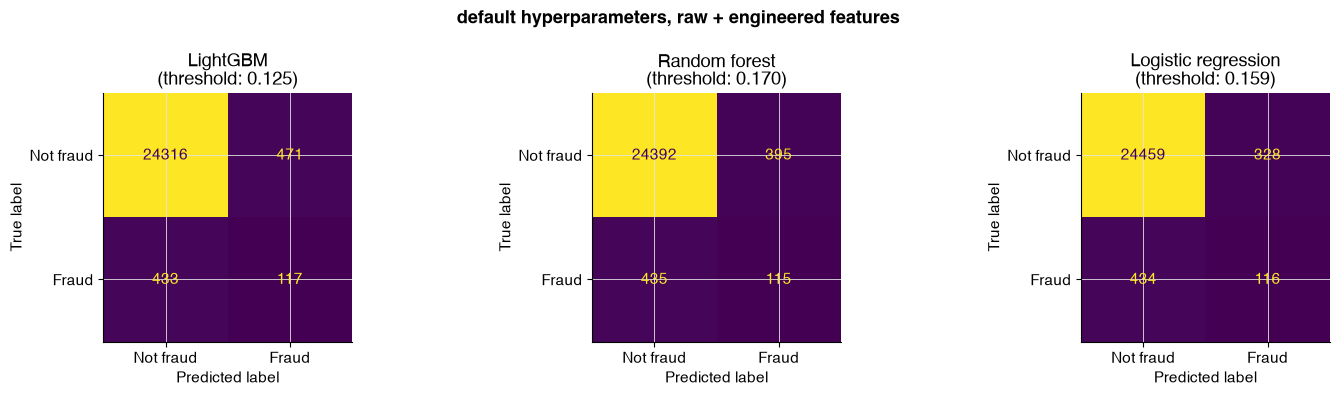

random-model PR-AUC on the test set = fraud rate = 0.0217
                     threshold  val_pr_auc  precision  recall      f1  pr_auc  \
model                                                                           
LightGBM                0.1254      0.1250     0.1990  0.2127  0.2056  0.1349   
Random forest           0.1700      0.1266     0.2255  0.2091  0.2170  0.1409   
Logistic regression     0.1589      0.1668     0.2613  0.2109  0.2334  0.1741   

                     roc_auc  
model                         
LightGBM              0.8363  
Random forest         0.8288  
Logistic regression   0.8533  


In [15]:
def build_pipeline(name, estimator, features, smote=False):
    """Preprocessing + model for the given feature columns (optionally with SMOTENC)."""
    numeric_cols = X[features].select_dtypes(include="number").columns.tolist()
    categorical_cols = [col for col in features if col not in numeric_cols]
    scale = name == "Logistic regression"

    if not smote:
        numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
        if scale:
            numeric_steps.append(("scaler", StandardScaler()))
        preprocess = ColumnTransformer([
            ("numeric", Pipeline(numeric_steps), numeric_cols),
            ("categorical", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore")),
            ]), categorical_cols),
        ])
        return Pipeline([("preprocess", preprocess), ("model", clone(estimator))])

    # SMOTENC needs complete data, so impute first (fit on the training partition only)
    impute_for_smote = ColumnTransformer(
        [
            ("numeric", SimpleImputer(strategy="median", keep_empty_features=True), numeric_cols),
            ("categorical", SimpleImputer(strategy="most_frequent", keep_empty_features=True), categorical_cols),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")
    preprocess = ColumnTransformer([
        ("numeric", StandardScaler() if scale else "passthrough", numeric_cols),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ])
    minority_count = int(y_sub_train.value_counts().min())
    return ImbPipeline([
        ("impute_for_smote", impute_for_smote),
        ("oversample", SMOTENC(
            categorical_features=categorical_cols,
            k_neighbors=min(5, minority_count - 1),
            random_state=42,
        )),
        ("preprocess", preprocess),
        ("model", clone(estimator)),
    ])


def evaluate(name, estimator, features=None, smote=False):
    """Fit Jan-Jul -> tune threshold on Aug-Sep -> refit Jan-Sep -> score Oct-Dec."""
    features = features or ALL_FEATURES
    pipeline = build_pipeline(name, estimator, features, smote)

    # 1. fit on Jan-Jul and find the optimal threshold on Aug-Sep
    pipeline.fit(X_sub_train[features], y_sub_train)
    val_probs = pipeline.predict_proba(X_val[features])[:, 1]
    threshold = find_best_threshold(y_val, val_probs)

    # 2. retrain on the full Jan-Sep training set before final evaluation
    pipeline.fit(X_train[features], y_train)
    probabilities = pipeline.predict_proba(X_test[features])[:, 1]

    # 3. apply the tuned threshold instead of the default 0.5
    predictions = (probabilities >= threshold).astype(int)

    metrics = {
        "model": name,
        "threshold": threshold,
        "val_pr_auc": average_precision_score(y_val, val_probs),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
        "pr_auc": average_precision_score(y_test, probabilities),
        "roc_auc": roc_auc_score(y_test, probabilities),
    }
    return metrics, pipeline, probabilities, predictions


def compare(models, features=None, smote=False, title=""):
    """Evaluate every model, plot confusion matrices, return the metrics table."""
    results, fitted = [], {}
    fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4))
    for (name, estimator), ax in zip(models.items(), np.atleast_1d(axes)):
        metrics, pipeline, probabilities, predictions = evaluate(name, estimator, features, smote)
        results.append(metrics)
        fitted[name] = (pipeline, probabilities, metrics["threshold"])
        ConfusionMatrixDisplay(
            confusion_matrix=confusion_matrix(y_test, predictions, labels=[0, 1]),
            display_labels=["Not fraud", "Fraud"],
        ).plot(ax=ax, colorbar=False, values_format="d")
        ax.set_title(f"{name}\n(threshold: {metrics['threshold']:.3f})")
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(results).set_index("model"), fitted


models = {
    "LightGBM": LGBMClassifier(random_state=42, verbosity=-1),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Logistic regression": LogisticRegression(max_iter=2000, random_state=42),
}

metrics_df, fitted = compare(models, title="default hyperparameters, raw + engineered features")
print(f"random-model PR-AUC on the test set = fraud rate = {y_test.mean():.4f}")
print(metrics_df.round(4))

### Ablation: do the engineered features help? ###
Same three models, same split, with only the raw dataset columns.

In [16]:
ablation = []
for name, estimator in models.items():
    for label, features in [("raw only", RAW_FEATURES), ("raw + engineered", ALL_FEATURES)]:
        metrics = evaluate(name, estimator, features)[0]
        ablation.append({"model": name, "features": label, **{k: metrics[k] for k in ["f1", "pr_auc", "roc_auc"]}})

ablation_df = pd.DataFrame(ablation).pivot(index="model", columns="features", values=["f1", "pr_auc", "roc_auc"])
ablation_df.round(4)

f1                    pr_auc           \
features            raw + engineered raw only raw + engineered raw only   
model                                                                     
LightGBM                      0.2056   0.2033           0.1349   0.1409   
Logistic regression           0.2334   0.2086           0.1741   0.1379   
Random forest                 0.2170   0.2055           0.1409   0.1418   

                             roc_auc           
features            raw + engineered raw only  
model                                          
LightGBM                      0.8363   0.8413  
Logistic regression           0.8533   0.8388  
Random forest                 0.8288   0.8288

- The engineered features clearly help **logistic regression** (F1 0.209 → 0.233, PR-AUC 0.138 → 0.174).
- They barely change the **tree models** (LightGBM PR-AUC 0.141 → 0.135, random forest unchanged).
- That makes sense: a tree can learn a cutoff like "distance > 100 km" on its own, while a linear model can't, so the flags give logistic regression the non-linear signal it was missing.

### Oversampling ###
- Going to try oversampling to hopefully help out and deal with some of the class imbalance. SMOTENC only resamples the training partition; the threshold is still tuned on the original, unresampled Aug–Sep data.

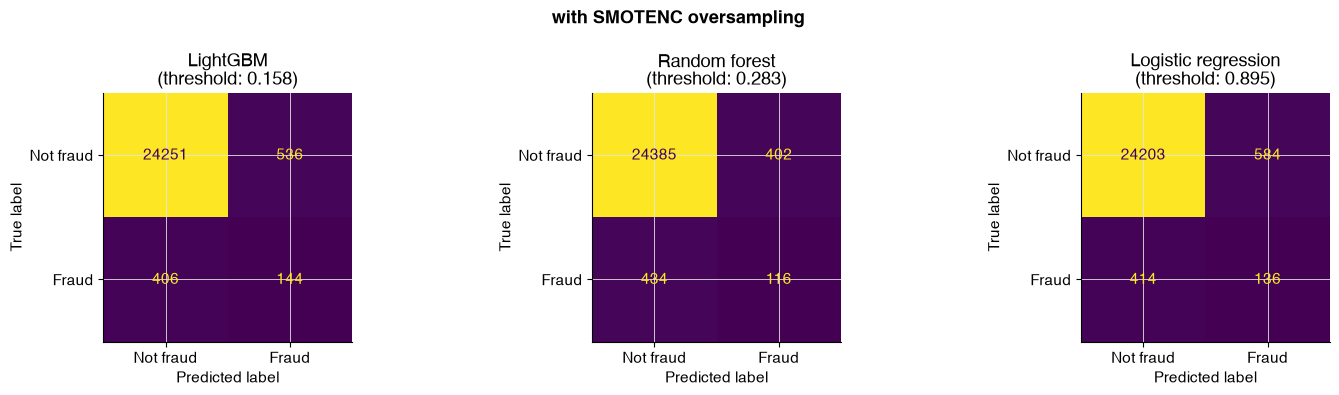

With Oversampling:
                     threshold  val_pr_auc  precision  recall      f1  pr_auc  \
model                                                                           
LightGBM                0.1576      0.1407     0.2118  0.2618  0.2341  0.1516   
Random forest           0.2833      0.1260     0.2239  0.2109  0.2172  0.1340   
Logistic regression     0.8948      0.1384     0.1889  0.2473  0.2142  0.1468   

                     roc_auc  
model                         
LightGBM              0.8414  
Random forest         0.8275  
Logistic regression   0.8314  


In [17]:
smotenc_metrics_df, _ = compare(models, smote=True, title="with SMOTENC oversampling")
print("With Oversampling:")
print(smotenc_metrics_df.round(4))

SMOTENC is not a consistent win: it helps default LightGBM (F1 0.206 → 0.234,
PR-AUC 0.135 → 0.152), leaves random forest about the same, and hurts logistic
regression (PR-AUC 0.174 → 0.147). Tuning the decision threshold already
handles most of the imbalance, so oversampling mostly shifts the predicted
probabilities rather than adding information.

### Hyperparameter Tuning ###
Random search scored by **validation PR-AUC** (fit on Jan–Jul, score on
Aug–Sep), so the test months are still untouched. The best setting per model
then goes through the same `evaluate` as before.

LightGBM: best val PR-AUC 0.1631 with {'subsample_freq': 1, 'subsample': 0.85, 'reg_lambda': 0, 'num_leaves': 7, 'n_estimators': 400, 'min_child_samples': 50, 'learning_rate': 0.03, 'colsample_bytree': 0.5}


Random forest: best val PR-AUC 0.1451 with {'min_samples_leaf': 20, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}


Logistic regression: best val PR-AUC 0.1694 with {'class_weight': 'balanced', 'C': 0.03}


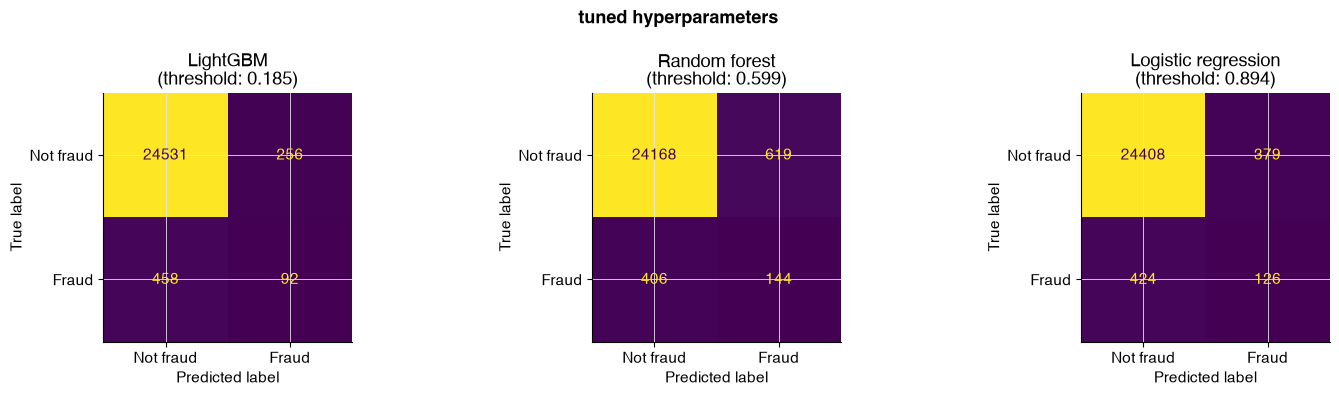

                     threshold  val_pr_auc  precision  recall      f1  pr_auc  \
model                                                                           
LightGBM                0.1853      0.1631     0.2644  0.1673  0.2049  0.1627   
Random forest           0.5991      0.1451     0.1887  0.2618  0.2193  0.1423   
Logistic regression     0.8937      0.1694     0.2495  0.2291  0.2389  0.1735   

                     roc_auc  
model                         
LightGBM              0.8527  
Random forest         0.8413  
Logistic regression   0.8528  


In [18]:
from sklearn.model_selection import ParameterSampler

search_spaces = {
    "LightGBM": (LGBMClassifier(random_state=42, verbosity=-1), {
        "n_estimators": [200, 400, 800],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "num_leaves": [7, 15, 31, 63],
        "min_child_samples": [20, 50, 100, 200],
        "subsample": [0.7, 0.85, 1.0],
        "subsample_freq": [1],
        "colsample_bytree": [0.5, 0.7, 0.9],
        "reg_lambda": [0, 1, 5, 10],
    }, 25),
    "Random forest": (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), {
        "min_samples_leaf": [1, 5, 20],
        "max_features": ["sqrt", 0.3],
        "class_weight": [None, "balanced_subsample"],
    }, 6),
    "Logistic regression": (LogisticRegression(max_iter=2000, random_state=42), {
        "C": [0.01, 0.03, 0.1, 0.3, 1, 3],
        "class_weight": [None, "balanced"],
    }, 12),
}

tuned_models, search_log = {}, []
for name, (estimator, space, n_iter) in search_spaces.items():
    best_score, best_params = -1, None
    for params in ParameterSampler(space, n_iter=n_iter, random_state=42):
        candidate = clone(estimator).set_params(**params)
        pipeline = build_pipeline(name, candidate, ALL_FEATURES).fit(X_sub_train, y_sub_train)
        score = average_precision_score(y_val, pipeline.predict_proba(X_val)[:, 1])
        search_log.append({"model": name, "val_pr_auc": score, **params})
        if score > best_score:
            best_score, best_params = score, params
    tuned_models[name] = clone(estimator).set_params(**best_params)
    print(f"{name}: best val PR-AUC {best_score:.4f} with {best_params}")

tuned_metrics_df, tuned_fitted = compare(tuned_models, title="tuned hyperparameters")
print(tuned_metrics_df.round(4))

In [19]:
# pick the final model by VALIDATION PR-AUC (choosing by test score would leak)
summary = pd.concat({
    "default": metrics_df,
    "SMOTENC": smotenc_metrics_df,
    "tuned": tuned_metrics_df,
}, names=["setup"]).round(4)
display(summary)

FINAL_NAME = tuned_metrics_df["val_pr_auc"].idxmax()
final_pipeline, final_probs, final_threshold = tuned_fitted[FINAL_NAME]
final_metrics = tuned_metrics_df.loc[FINAL_NAME]
print(f"final model: tuned {FINAL_NAME}")
print(final_metrics.round(4).to_string())

threshold  val_pr_auc  precision  recall      f1  \
setup   model                                                                   
default LightGBM                0.1254      0.1250     0.1990  0.2127  0.2056   
        Random forest           0.1700      0.1266     0.2255  0.2091  0.2170   
        Logistic regression     0.1589      0.1668     0.2613  0.2109  0.2334   
SMOTENC LightGBM                0.1576      0.1407     0.2118  0.2618  0.2341   
        Random forest           0.2833      0.1260     0.2239  0.2109  0.2172   
        Logistic regression     0.8948      0.1384     0.1889  0.2473  0.2142   
tuned   LightGBM                0.1853      0.1631     0.2644  0.1673  0.2049   
        Random forest           0.5991      0.1451     0.1887  0.2618  0.2193   
        Logistic regression     0.8937      0.1694     0.2495  0.2291  0.2389   

                             pr_auc  roc_auc  
setup   model                                 
default LightGBM             0.1349   0.8363  
        Random forest        0.1409   0.8288  
        Logistic regression  0.1741   0.8533  
SMOTENC LightGBM             0.1516   0.8414  
        Random forest        0.1340   0.8275  
        Logistic regression  0.1468   0.8314  
tuned   LightGBM             0.1627   0.8527  
        Random forest        0.1423   0.8413  
        Logistic regression  0.1735   0.8528

final model: tuned Logistic regression
threshold     0.8937
val_pr_auc    0.1694
precision     0.2495
recall        0.2291
f1            0.2389
pr_auc        0.1735
roc_auc       0.8528


- Tuning helped LightGBM the most (PR-AUC 0.135 → 0.163, ROC-AUC 0.836 → 0.853). The best setting uses very small trees (7 leaves), another sign the signal is fairly simple.
- **Final model: tuned logistic regression** (`C=0.03`, balanced class weights), chosen because it has the best **validation** PR-AUC. On the Oct–Dec test set: **F1 0.239, precision 0.25, recall 0.23, PR-AUC 0.174 (8x a random model's 0.022), ROC-AUC 0.853**.
- Its threshold (0.89) is high because balanced class weights push every probability up; only the ranking matters.
- The top models are within ~0.01 PR-AUC of each other, which is about the noise level with 550 test frauds, so a simple, explainable logistic regression is a reasonable pick.

### Explaining the Model (SHAP) ###
SHAP values show how much each feature pushed each test transaction's score up
or down. One-hot columns are summed back into their original feature.

Background dataset has 2000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2000 when initializing the masker.


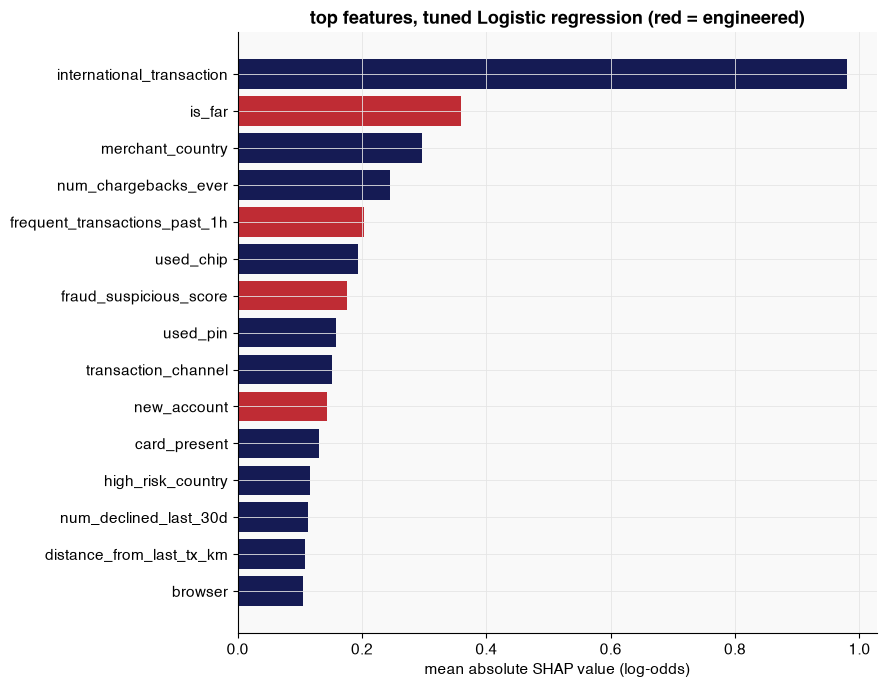

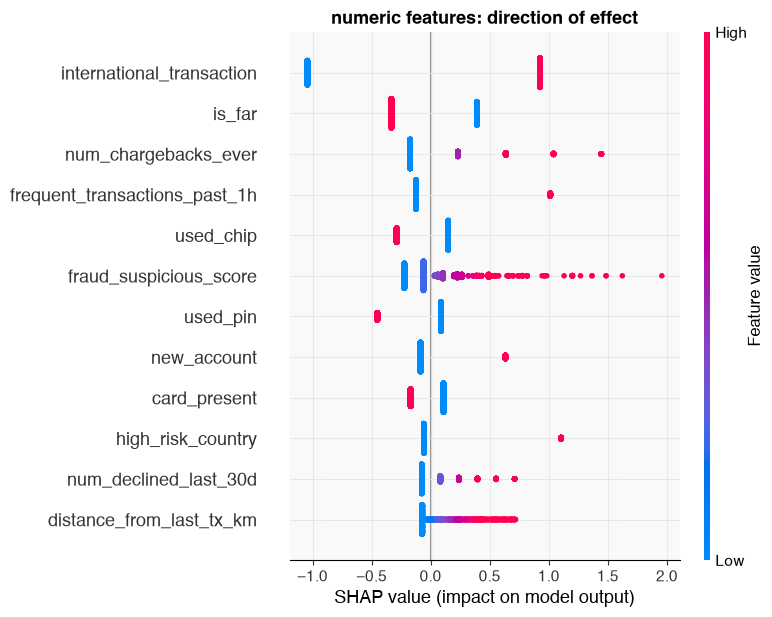

international_transaction        0.9792
is_far                           0.3584
merchant_country                 0.2965
num_chargebacks_ever             0.2450
frequent_transactions_past_1h    0.2023
used_chip                        0.1940
fraud_suspicious_score           0.1762
used_pin                         0.1589
transaction_channel              0.1524
new_account                      0.1430
card_present                     0.1314
high_risk_country                0.1156
num_declined_last_30d            0.1127
distance_from_last_tx_km         0.1078
browser                          0.1048


In [20]:
import shap

preprocess = final_pipeline.named_steps["preprocess"]
final_model = final_pipeline.named_steps["model"]
feature_names = preprocess.get_feature_names_out()

rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_test), size=min(3000, len(X_test)), replace=False)
X_test_enc = preprocess.transform(X_test.iloc[sample_idx])
X_test_enc = X_test_enc.toarray() if hasattr(X_test_enc, "toarray") else X_test_enc

if isinstance(final_model, LogisticRegression):
    background = preprocess.transform(X_train.sample(2000, random_state=42))
    background = background.toarray() if hasattr(background, "toarray") else background
    explainer = shap.LinearExplainer(final_model, background)
    shap_values = explainer.shap_values(X_test_enc)
else:
    explainer = shap.TreeExplainer(final_model)
    shap_values = explainer.shap_values(X_test_enc)
    if isinstance(shap_values, list):  # older shap: one array per class
        shap_values = shap_values[1]
    elif shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]

# map "numeric__x" / "categorical__merchant_country_Russia" back to the original column
categorical_inputs = [col for col in ALL_FEATURES if col not in X.select_dtypes(include="number").columns]
def original_feature(encoded):
    stage, column = encoded.split("__", 1)
    if stage == "categorical":
        return next(col for col in sorted(categorical_inputs, key=len, reverse=True) if column.startswith(col + "_"))
    return column

shap_df = pd.DataFrame(shap_values, columns=feature_names)
grouped = shap_df.T.groupby(original_feature).sum().T
importance = grouped.abs().mean().sort_values(ascending=False)

top = importance.head(15)[::-1]
plt.figure(figsize=(9, 7))
plt.barh(top.index, top.values, color=[RED if f in ENGINEERED else BLUE for f in top.index])
plt.xlabel("mean absolute SHAP value (log-odds)")
plt.title(f"top features, tuned {FINAL_NAME} (red = engineered)", fontweight="bold")
plt.tight_layout()
plt.show()

numeric_names = [n for n in feature_names if n.startswith("numeric__")]
numeric_idx = [list(feature_names).index(n) for n in numeric_names]
shap.summary_plot(
    shap_values[:, numeric_idx],
    X_test_enc[:, numeric_idx],
    feature_names=[n.split("__", 1)[1] for n in numeric_names],
    max_display=12,
    show=False,
)
plt.title("numeric features: direction of effect", fontweight="bold")
plt.tight_layout()
plt.show()

print(importance.head(15).round(4).to_string())

- `international_transaction` is by far the biggest driver, followed by `is_far`, `merchant_country`, `num_chargebacks_ever` and `frequent_transactions_past_1h`.
- 4 of the top 10 features are engineered (`is_far`, `frequent_transactions_past_1h`, `fraud_suspicious_score`, `new_account`), which matches the ablation: the flags carry real signal for this model.
- Chip, PIN and card-present transactions push the score down.

### Business Impact: Fraud Dollars Caught vs. False Alarms ###
A fraud team can only review so many alerts. Using `fraud_amount_lost` as the
money at stake, this shows how much fraud the final model catches in Oct–Dec
at different **alert budgets** (the share of transactions it flags for review),
and at the F1-tuned threshold from validation.

total fraud $ in Oct-Dec: $80,328 across 550 fraud transactions (25337 total)


,alerts per 1k tx,false alarms per 1k tx,precision,fraud cases caught,fraud $ caught,share of fraud $ caught
top 0.5% flagged,5.0,3.2,37.0%,47 / 550,"$4,624",5.8%
top 1.0% flagged,10.0,6.9,31.1%,79 / 550,"$9,221",11.5%
top 2.0% flagged,20.0,15.0,25.0%,127 / 550,"$25,071",31.2%
top 5.0% flagged,50.0,41.7,16.6%,210 / 550,"$40,444",50.3%
top 10.0% flagged,100.0,88.2,11.8%,300 / 550,"$54,158",67.4%
F1 threshold (0.894),19.9,15.0,25.0%,126 / 550,"$25,068",31.2%


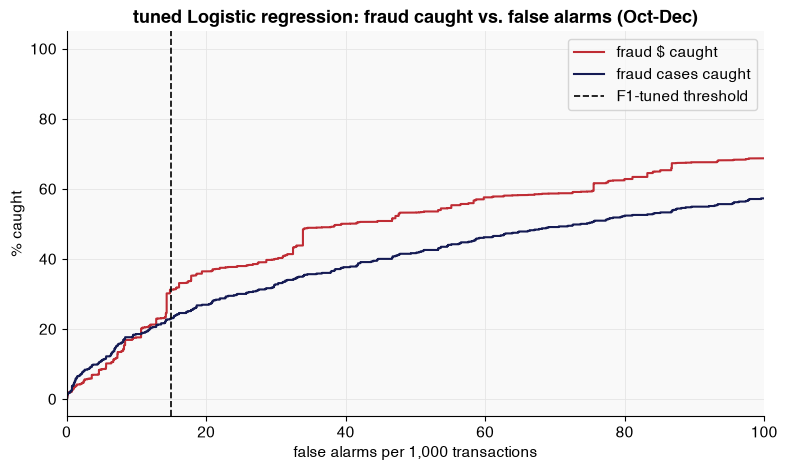

In [21]:
test_data = data.loc[test_mask].assign(score=final_probs)
total_fraud_dollars = test_data.loc[test_data["is_fraud"] == 1, "fraud_amount_lost"].sum()
n_test = len(test_data)

def impact(flagged):
    caught = flagged & (test_data["is_fraud"] == 1)
    false_alarms = flagged & (test_data["is_fraud"] == 0)
    return {
        "alerts per 1k tx": flagged.sum() / n_test * 1000,
        "false alarms per 1k tx": false_alarms.sum() / n_test * 1000,
        "precision": caught.sum() / max(flagged.sum(), 1),
        "fraud cases caught": f"{caught.sum()} / {test_data['is_fraud'].sum()}",
        "fraud $ caught": test_data.loc[caught, "fraud_amount_lost"].sum(),
        "share of fraud $ caught": test_data.loc[caught, "fraud_amount_lost"].sum() / total_fraud_dollars,
    }

rows = {}
for budget in [0.005, 0.01, 0.02, 0.05, 0.10]:
    cutoff = test_data["score"].quantile(1 - budget)
    rows[f"top {budget:.1%} flagged"] = impact(test_data["score"] >= cutoff)
rows[f"F1 threshold ({final_threshold:.3f})"] = impact(test_data["score"] >= final_threshold)

impact_df = pd.DataFrame(rows).T
print(f"total fraud $ in Oct-Dec: ${total_fraud_dollars:,.0f} across {test_data['is_fraud'].sum()} fraud transactions ({n_test} total)")
display(impact_df.style.format({
    "alerts per 1k tx": "{:.1f}",
    "false alarms per 1k tx": "{:.1f}",
    "precision": "{:.1%}",
    "fraud $ caught": "${:,.0f}",
    "share of fraud $ caught": "{:.1%}",
}))

# curve: share of fraud $ caught vs false alarms, sweeping the alert budget
order = test_data.sort_values("score", ascending=False)
cum_dollars = (order["fraud_amount_lost"] * order["is_fraud"]).cumsum() / total_fraud_dollars
cum_false = (1 - order["is_fraud"]).cumsum() / n_test * 1000
cum_cases = order["is_fraud"].cumsum() / order["is_fraud"].sum()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(cum_false.values, cum_dollars.values * 100, color=RED, label="fraud $ caught")
ax.plot(cum_false.values, cum_cases.values * 100, color=BLUE, label="fraud cases caught")
f1_false = rows[f"F1 threshold ({final_threshold:.3f})"]["false alarms per 1k tx"]
ax.axvline(f1_false, color="black", linestyle="--", linewidth=1.2, label="F1-tuned threshold")
ax.set_xlim(0, 100)
ax.set_xlabel("false alarms per 1,000 transactions")
ax.set_ylabel("% caught")
ax.set_title(f"tuned {FINAL_NAME}: fraud caught vs. false alarms (Oct-Dec)", fontweight="bold")
ax.legend()
plt.show()

- Oct–Dec has **$80,328** of fraud across 550 fraud transactions (25,337 total).
- At the F1-tuned threshold the model flags about **2% of transactions (20 per 1,000)**. 1 in 4 alerts is real fraud, and it catches **126 of 550 fraud cases and $25,068 (31%) of fraud dollars** at **15 false alarms per 1,000 transactions**.
- With a bigger review team, flagging the top 5% catches **half of all fraud dollars** at 42 false alarms per 1,000.
- The share of dollars caught grows faster than the share of cases: the model tends to catch the larger frauds first.

## Conclusion ##
- Built a fraud classifier with a **date-based split** (train Jan–Sep, test Oct–Dec), thresholds and hyperparameters chosen on a held-out Aug–Sep period, and EDA cutoffs taken from training months only, so the test score is an honest estimate of future performance.
- Compared LightGBM, random forest and logistic regression with and without engineered features and SMOTENC oversampling. The tuned logistic regression wins on validation and reaches **PR-AUC 0.174 (8x random)** and **ROC-AUC 0.853** on the test months.
- Engineered features help the linear model most; oversampling is not a reliable improvement here.
- In business terms: reviewing 2% of transactions catches **31% of fraud dollars**; reviewing 5% catches **half**.

**Limitations and next steps**
- F1 around 0.24 means most fraud still slips through at the chosen threshold. Each feature is only weakly related to fraud on its own.
- The dataset is synthetic, so real-world results would differ.
- Next: features that compare a transaction with **that card's own history** (its usual countries, hours and amounts), a threshold chosen from real review costs, and probability calibration.